In [115]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize_scalar

In [116]:
df = pd.read_csv('Merged_pop_reserv_all_more_5.csv',index_col=0)
New_york = df.loc[df['POPESTIMATE2019']> 10000000].index.values
df = df.drop(New_york)

In [117]:
df.columns

Index(['city', 'STNAME', 'POPESTIMATE2019', '#_of_reservations',
       'Per_capita_rate', 'POPEST2019LOG'],
      dtype='object')

In [126]:
# take values x and y values from the 
x_list = []
for pop in df['POPESTIMATE2019']:
    x_list.append(int(pop))
x = np.array(x_list)
y_list = []
for reservation in df['Per_capita_rate']:
    y_list.append(reservation)
y = np.array(y_list)

In [127]:
y

array([0.00081154, 0.00046006, 0.00029979, ..., 0.00034061, 0.001199  ,
       0.0334728 ])

In [128]:
#defining a cost function: a measure of the ‘goodness’ of the linear relation that we want to maximize.A good indicator is the Pearson product-moment correlation coefficient r, which identifies the strength of the linear correlation between two variables.
def cost_function(e):
    #y and x are already defined
    r = np.corrcoef(y,x**e) #returns correlation matrix
    #print each iteration
    print('r value: {:0.4f} exp: {:.4f}'.format(r[0][1],e)) 
    return -abs(r[0][1])

In [129]:
minimize_scalar(cost_function)

r value: nan exp: 0.0000
r value: -0.0649 exp: 1.0000
r value: -0.0091 exp: 2.6180
r value: -0.0649 exp: 1.0000
r value: -0.0214 exp: 1.6180
r value: -0.1443 exp: 0.6180
r value: -0.2231 exp: 0.3820
r value: -0.2831 exp: 0.2361
r value: -0.3244 exp: 0.1459
r value: -0.3515 exp: 0.0902
r value: -0.3688 exp: 0.0557
r value: -0.3797 exp: 0.0344
r value: -0.3865 exp: 0.0213
r value: -0.3908 exp: 0.0132
r value: -0.3934 exp: 0.0081
r value: -0.3950 exp: 0.0050
r value: -0.3961 exp: 0.0031
r value: -0.3967 exp: 0.0019
r value: -0.3971 exp: 0.0012
r value: -0.3973 exp: 0.0007
r value: -0.3974 exp: 0.0005
r value: -0.3975 exp: 0.0003
r value: -0.3976 exp: 0.0002
r value: -0.3976 exp: 0.0001
r value: -0.3977 exp: 0.0001
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 exp: 0.0000
r value: -0.3977 e

     fun: -0.3976880517322267
    nfev: 55
     nit: 51
 success: True
       x: 1.432458752577423e-09

In [130]:
exp_x = []
for lin in x_list:
    lin_x = lin**1.432458752577423e-09
    exp_x.append(lin_x)

In [131]:
df['Trans_pop'] = exp_x
exp_x_nump = np.array(exp_x).reshape((-1, 1))

<AxesSubplot:xlabel='Trans_pop', ylabel='Per_capita_rate'>

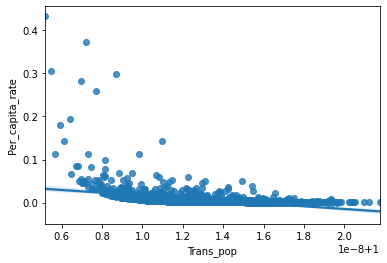

In [132]:
import seaborn as sns
sns.regplot(x='Trans_pop',y='Per_capita_rate',data=df)

In [137]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
model = LinearRegression()
model.fit(exp_x_nump, y)
r_sq = model.score(exp_x_nump, y)
print('coefficient of determination:', r_sq)


coefficient of determination: 0.15815578672960728


In [138]:
print('slope:', model.coef_)
print('intercept:', model.intercept_)

slope: [-3147671.95537004]
intercept: 3147672.003444701


In [139]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
transformer = PolynomialFeatures(degree=2, include_bias=False)
transformer.fit(exp_x_nump)
x_ = transformer.transform(exp_x_nump)
model = LinearRegression().fit(x_, y)
r_sq = model.score(x_, y)
print('coefficient of determination:', r_sq)

print('intercept:', model.intercept_)

print('coefficients:', model.coef_)


coefficient of determination: 0.1583458628274167
intercept: -338740906952.6906
coefficients: [ 6.77484954e+11 -3.38744047e+11]
